## Olist E-Commerce: Data Exploration with DuckDB

## 1. Setup the notebook

In this notebook we load five tables of the e-commerce dataset into DuckDB and explore them with SQL before designing a data warehouse.

**What we will do**

1. Load the CSV files into DuckDB
2. Understand each table: structure, grain, keys
3. Check the relationships (foreign keys)
4. Find data quality issues
5. Build a star schema

**Tables:** `customers`, `orders`, `order_items`, `products`, `sellers`

In [1]:
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
WAREHOUSE_DIR = DATA_DIR / "warehouse"
csv = RAW_DIR / "olist_orders_dataset.csv"

In [3]:
print(duckdb.sql(f"SELECT count(*) FROM '{csv}'"))

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│        99441 │
└──────────────┘



### DuckDB lets query CSV data with SQL. The database file persists locally so later notebooks can reuse the loaded raw tables.

In [4]:
DB_PATH = WAREHOUSE_DIR / "ecommerce.duckdb"
con = duckdb.connect(str(DB_PATH))

In [5]:
def q(sql_str: str) -> pd.DataFrame:
    """Run a SQL query in DuckDB and return a pandas DataFrame."""
    return con.sql(sql_str).df()

## 2. Load the source tables into a **raw schema**

A Schema is a namespace that groups tables. We keep the source copies in **raw**
so that they remain distinguishable from cleaned warehouse tables we will create later.

### Define a mapping to transform column types

In [6]:
RAW_TABLES: dict[str, dict[str, str]] = {
    "customers": {"customer_zip_code_prefix": "VARCHAR"},  # keep leading zeros
    "orders": {},
    "order_items": {},
    "products": {},
    "sellers": {}
}

### Define some helper functions

In [7]:
def csv_path(table: str) -> Path:
    """"""
    return RAW_DIR / f"olist_{table}_dataset.csv"

def check_source_files(tables) -> None:
    """Fail once, list every missing file"""
    missing = [csv_path(t) for t in tables if not csv_path(t).exists()]
    if missing:
        names = "\n".join(f" - {p}" for p in missing)
        raise FileNotFoundError(f"Missing CSV files: {names}")

#### Define schema name for source data

In [8]:
RAW_SCHEMA = "raw"

### Load data into source tables

In [9]:
def load_raw_table(con: duckdb.DuckDBPyConnection, table: str, column_types: dict[str, str]) -> int:
    target = f'{RAW_SCHEMA}."{table}"'
    source = con.read_csv(str(csv_path(table)), header=True, dtype=column_types or None)
    con.execute(f"DROP TABLE IF EXISTS {target}")
    source.to_table(target)
    return con.execute(f"SELECT count(*) FROM {target}").fetchone()[0]

### Sanity check if we have all required source files

In [10]:
check_source_files(RAW_TABLES)

### Create **RAW_SCHEMA** if it does not exist

In [11]:
con.execute(f"CREATE SCHEMA IF NOT EXISTS {RAW_SCHEMA}")

### Execute **load_raw_table** to load all source data

In [12]:
row_counts = {t: load_raw_table(con, t, types) for t, types in RAW_TABLES.items()}

### Check count of rows inserted into each `raw`.`<table>`

In [13]:
pd.DataFrame(row_counts.items(), columns=["table_name", "row_count"])

,table_name,row_count
0,customers,99441
1,orders,99441
2,order_items,112650
3,products,32951
4,sellers,3095


## 3. Look at each table

For every table we ask: **what does one row represent?** This is the *grain*. Getting the grain right is the most important step in dimensional modeling.

In [14]:
for t in RAW_TABLES:
    print(f"----- {t} -----")
    display(q(f"DESCRIBE raw.{t}")[["column_name", "column_type", "null"]])
    display(q(f"SELECT * FROM raw.{t} LIMIT 5"))

----- customers -----


,column_name,column_type,null
0,customer_id,VARCHAR,YES
1,customer_unique_id,VARCHAR,YES
2,customer_zip_code_prefix,VARCHAR,YES
3,customer_city,VARCHAR,YES
4,customer_state,VARCHAR,YES


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


----- orders -----


,column_name,column_type,null
0,order_id,VARCHAR,YES
1,customer_id,VARCHAR,YES
2,order_status,VARCHAR,YES
3,order_purchase_timestamp,TIMESTAMP,YES
4,order_approved_at,TIMESTAMP,YES
5,order_delivered_carrier_date,TIMESTAMP,YES
6,order_delivered_customer_date,TIMESTAMP,YES
7,order_estimated_delivery_date,TIMESTAMP,YES


...

,column_name,column_type,null
0,product_id,VARCHAR,YES
1,product_category_name,VARCHAR,YES
2,product_name_lenght,BIGINT,YES
3,product_description_lenght,BIGINT,YES
4,product_photos_qty,BIGINT,YES
5,product_weight_g,BIGINT,YES
6,product_length_cm,BIGINT,YES
7,product_height_cm,BIGINT,YES
8,product_width_cm,BIGINT,YES


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40,287,1,225,16,10,14
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44,276,1,1000,30,18,20
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46,250,1,154,18,9,15
3,cef67bcfe19066a932b7673e239eb23d,bebes,27,261,1,371,26,4,26
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37,402,4,625,20,17,13


----- sellers -----


,column_name,column_type,null
0,seller_id,VARCHAR,YES
1,seller_zip_code_prefix,VARCHAR,YES
2,seller_city,VARCHAR,YES
3,seller_state,VARCHAR,YES


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,04195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


### Grain of each table (Task 1a)

| table | one row represents | rows |
|---|---|---|
| `customers` | one customer **record attached to one order** (`customer_id`); the same person can appear several times under different `customer_id`s but the same `customer_unique_id` | 99,441 |
| `orders` | one order placed on the platform, with its status and lifecycle timestamps | 99,441 |
| `order_items` | one **line item** of an order: item number `order_item_id` (1, 2, 3...) inside an order, for one product sold by one seller, with its price and freight | 112,650 |
| `products` | one product in the catalogue, with its category and physical attributes | 32,951 |
| `sellers` | one seller (merchant), with its location | 3,095 |

`SUMMARIZE`profiles every column is one command: min, max, average, null percentage,
approximate distinct count.

In [15]:
q("SUMMARIZE raw.orders")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,order_id,VARCHAR,00010242fe8c5a6d1ba2dd792cb16214,fffe41c64501cc87c801fd61db3f6244,87618,NaN,<NA>,NaN,NaN,NaN,99441,0.00
1,customer_id,VARCHAR,00012a2ce6f8dcda20d059ce98491703,ffffe8b65bbe3087b653a978c870db99,101221,NaN,<NA>,NaN,NaN,NaN,99441,0.00
2,order_status,VARCHAR,approved,unavailable,9,NaN,<NA>,NaN,NaN,NaN,99441,0.00
3,order_purchase_timestamp,TIMESTAMP,2016-09-04 21:15:19,2018-10-17 17:30:18,93884,2017-12-31 08:43:12.776581,<NA>,2017-09-12 09:46:15.721942,2018-01-19 08:25:16.131472,2018-05-04 21:22:52.465787,99441,0.00
4,order_approved_at,TIMESTAMP,2016-09-15 12:16:38,2018-09-03 17:40:06,100122,2017-12-31 18:35:24.0988,<NA>,2017-09-12 23:38:47.244113,2018-01-19 19:31:11.91185,2018-05-05 10:39:06.448894,99441,0.16
5,order_delivered_carrier_date,TIMESTAMP,2016-10-08 10:34:01,2018-09-11 19:48:28,79693,2018-01-04 21:49:48.138278,<NA>,2017-09-17 05:01:14.896067,2018-01-24 13:03:07.097667,2018-05-08 03:14:38.982959,99441,1.79
6,order_delivered_customer_date,TIMESTAMP,2016-10-11 13:46:32,2018-10-17 13:22:46,89604,2018-01-14 12:09:19.035543,<NA>,2017-09-25 19:42:45.079512,2018-02-03 08:46:48.115237,2018-05-16 04:30:00.070728,99441,2.98
7,order_estimated_delivery_date,TIMESTAMP,2016-09-30 00:00:00,2018-11-12 00:00:00,440,2018-01-24 03:08:37.730111,<NA>,2017-10-03 07:03:45.764487,2018-02-14 12:08:43.90428,2018-05-26 07:48:29.412611,99441,0.00


In [16]:
q("SUMMARIZE raw.order_items")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,order_id,VARCHAR,00010242fe8c5a6d1ba2dd792cb16214,fffe41c64501cc87c801fd61db3f6244,87618,NaN,NaN,NaN,NaN,NaN,112650,0.0
1,order_item_id,BIGINT,1,21,21,1.1978339991122948,0.7051240313951734,1,1,1,112650,0.0
2,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,112650,0.0
3,seller_id,VARCHAR,0015a82c2db000af6aaaf3ae2ecb0532,ffff564a4f9085cd26170f4732393726,3886,NaN,NaN,NaN,NaN,NaN,112650,0.0
4,shipping_limit_date,TIMESTAMP,2016-09-19 00:15:34,2020-04-09 22:35:08,80774,2018-01-07 15:36:52.192685,NaN,2017-09-20 14:24:06.919554,2018-01-27 19:47:01.503972,2018-05-11 00:22:53.928243,112650,0.0
5,price,DOUBLE,0.85,6735.0,6497,120.65373901477311,183.6339280502597,40.01666999532123,74.5760959518914,134.19097071958893,112650,0.0
6,freight_value,DOUBLE,0.0,409.68,5665,19.99031992898562,15.806405412296998,13.071531156591233,16.279508106244666,21.16306476327699,112650,0.0


In [17]:
q("SUMMARIZE raw.products")

,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,product_id,VARCHAR,00066f42aeeb9f3007548bb9d3f33c38,fffe9eeff12fcbd74a2f2b007dde0c58,24292,NaN,NaN,NaN,NaN,NaN,32951,0.00
1,product_category_name,VARCHAR,agro_industria_e_comercio,utilidades_domesticas,66,NaN,NaN,NaN,NaN,NaN,32951,1.85
2,product_name_lenght,BIGINT,5,76,64,48.47694876472589,10.245740725237287,42,51,57,32951,1.85
3,product_description_lenght,BIGINT,4,3992,2781,771.4952846232337,635.1152246349538,339,594,973,32951,1.85
4,product_photos_qty,BIGINT,1,20,20,2.1889861166939797,1.7367656379315435,1,1,3,32951,1.85
5,product_weight_g,BIGINT,0,40425,2155,2276.4724877841513,4282.038730977024,300,701,1883,32951,0.01
6,product_length_cm,BIGINT,7,105,97,30.81507784758263,16.914458054065953,18,25,39,32951,0.01
7,product_height_cm,BIGINT,2,105,99,16.937661234028347,13.637554061749569,8,13,21,32951,0.01
8,product_width_cm,BIGINT,6,118,92,23.196728277034204,12.079047453227794,15,20,30,32951,0.01


## 4. Primary Keys

A **primary key** uniquely identifies a row. A column is a valid candidate only if `count(*) = count(distinct ...)` and it has no nulls.

- A **composite key** uses several columns together (`order_items`)
- A **natural key** comes from the business (`customer_unique_id`).
- A **surrogate key** is generated by the warehouse (`customer_key = 1, 2, 3...`)

In [18]:
q("""
SELECT 'customers.customer_id'         AS candidate, count(*) AS n, count(DISTINCT customer_id) AS n_distinct FROM raw.customers
UNION ALL SELECT 'customers.customer_unique_id',         count(*), count(DISTINCT customer_unique_id) FROM raw.customers
UNION ALL SELECT 'orders.order_id',                      count(*), count(DISTINCT order_id) FROM raw.orders
UNION ALL SELECT 'order_items.order_id (alone)',         count(*), count(DISTINCT order_id) FROM raw.order_items
UNION ALL SELECT 'order_items(order_id, order_item_id)', count(*), count(DISTINCT (order_id, order_item_id)) FROM raw.order_items
UNION ALL SELECT 'products.product_id',                  count(*), count(DISTINCT product_id) FROM raw.products
UNION ALL SELECT 'sellers.seller_id',                    count(*), count(DISTINCT seller_id) FROM raw.sellers
""")

,candidate,n,n_distinct
0,customers.customer_id,99441,99441
1,customers.customer_unique_id,99441,96096
2,orders.order_id,99441,99441
3,order_items.order_id (alone),112650,98666
4,"order_items(order_id, order_item_id)",112650,112650
5,products.product_id,32951,32951
6,sellers.seller_id,3095,3095


A primary key also needs **no nulls**. We check every key column:

In [19]:
q("""
SELECT 'customers.customer_id' AS key_column, count(*) FILTER (customer_id IS NULL) AS n_null FROM raw.customers
UNION ALL SELECT 'orders.order_id',          count(*) FILTER (order_id IS NULL)      FROM raw.orders
UNION ALL SELECT 'order_items.order_id',     count(*) FILTER (order_id IS NULL)      FROM raw.order_items
UNION ALL SELECT 'order_items.order_item_id', count(*) FILTER (order_item_id IS NULL) FROM raw.order_items
UNION ALL SELECT 'products.product_id',      count(*) FILTER (product_id IS NULL)    FROM raw.products
UNION ALL SELECT 'sellers.seller_id',        count(*) FILTER (seller_id IS NULL)     FROM raw.sellers
""")

,key_column,n_null
0,customers.customer_id,0
1,orders.order_id,0
2,order_items.order_id,0
3,order_items.order_item_id,0
4,products.product_id,0
5,sellers.seller_id,0


**Result:** `customer_id`, `order_id`, `product_id` and `seller_id` each have `n = n_distinct` and no nulls, so they
are the primary keys of their tables. In `order_items`, `order_id` alone repeats (an order can have several items),
but the pair **(`order_id`, `order_item_id`)** is unique and null-free: it is a **composite primary key**.
`customer_unique_id` is *not* unique in `customers` (99,441 rows, 96,096 distinct values), so it cannot be the key of that table.

## 4. Foreign key relationships

```
customers 1 ---- N orders 1 ---- N order_items N ---- 1 products
```

A foreign key is healthy when every value exists in the parent table. An **orphan** is
a child row with no parent.

In [20]:
q("""
SELECT 'orders without customer' AS check_name, count(*) AS n
  FROM raw.orders o ANTI JOIN raw.customers c USING (customer_id)
UNION ALL SELECT 'items without order', count(*)
  FROM raw.order_items i ANTI JOIN raw.orders o USING (order_id)
UNION ALL SELECT 'items without product', count(*)
  FROM raw.order_items i ANTI JOIN raw.products p USING (product_id)
UNION ALL SELECT 'items without seller', count(*)
    FROM raw.order_items i ANTI JOIN raw.sellers s USING (seller_id)
UNION ALL SELECT 'orders without items', count(*)
  FROM raw.orders o ANTI JOIN raw.order_items i USING (order_id)
""")

,check_name,n
0,orders without customer,0
1,items without order,0
2,items without product,0
3,items without seller,0
4,orders without items,775


No orphans in the child-to-parent direction. But 775 orders have no items. An **INNER JOIN** from orders
to items would silently remove them.

| relationship | parent (PK) | child (FK) | linking column |
|---|---|---|---|
| customer places order | `customers` | `orders` | `customer_id` |
| order contains item | `orders` | `order_items` | `order_id` |
| product is sold as item | `products` | `order_items` | `product_id` |
| seller sells item | `sellers` | `order_items` | `seller_id` |

`order_items` is the child in three relationships: it is the **junction table** that resolves the hidden
many-to-many relationships orders ↔ products and orders ↔ sellers.

## 5. Data Quality

we check five dimensions: completeness(nulls), uniqueness, validity (values in a sensible range),
consistency (fields agree), timeliness (coverage)

### 5.1 Orders with no items

#### Exercise 1

In [21]:
q("""
SELECT o.order_status, count(*) AS orders_without_items
FROM raw.orders o
ANTI JOIN raw.order_items i USING (order_id)
GROUP BY o.order_status
ORDER BY orders_without_items DESC
""")

,order_status,orders_without_items
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


**Finding:** Almost all orders without items are `unavailable` or `canceled`, i.e. orders that never got fulfilled. They are real orders, so a fact table built with an INNER JOIN to `order_items` would lose them.

### 5.2 Check order status and class imbalance

#### Exercise 2

In [22]:
q("""
SELECT order_status,
       count(*) AS n,
       round(100.0 * count(*) / sum(count(*)) OVER (), 2) AS pct
FROM raw.orders
GROUP BY order_status
ORDER BY n DESC
""")

,order_status,n,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


**Finding:** The status column is heavily imbalanced: 97% of the orders are `delivered`. Any metric or model about the other statuses is based on very few rows.

### 5.3 Missing and inconsistent timestamps

#### Exercise 3

In [23]:
q("""
SELECT count(*) FILTER (order_approved_at IS NULL)                                    AS approved_null,
       count(*) FILTER (order_delivered_carrier_date IS NULL)                         AS carrier_null,
       count(*) FILTER (order_delivered_customer_date IS NULL)                        AS delivered_null,
       count(*) FILTER (order_status = 'delivered'
                        AND order_delivered_customer_date IS NULL)                    AS delivered_but_no_date,
       count(*) FILTER (order_delivered_carrier_date > order_delivered_customer_date) AS carrier_after_customer
FROM raw.orders
""")

,approved_null,carrier_null,delivered_null,delivered_but_no_date,carrier_after_customer
0,160,1783,2965,8,23


**Finding:** Missing timestamps are mostly expected (orders not yet approved, shipped or delivered), but 8 orders are `delivered` without a delivery date and 23 orders reach the customer *before* the carrier picked them up. These rows are inconsistent and must be flagged before computing delivery times.

### 5.4 Time coverage

#### Exercise 4

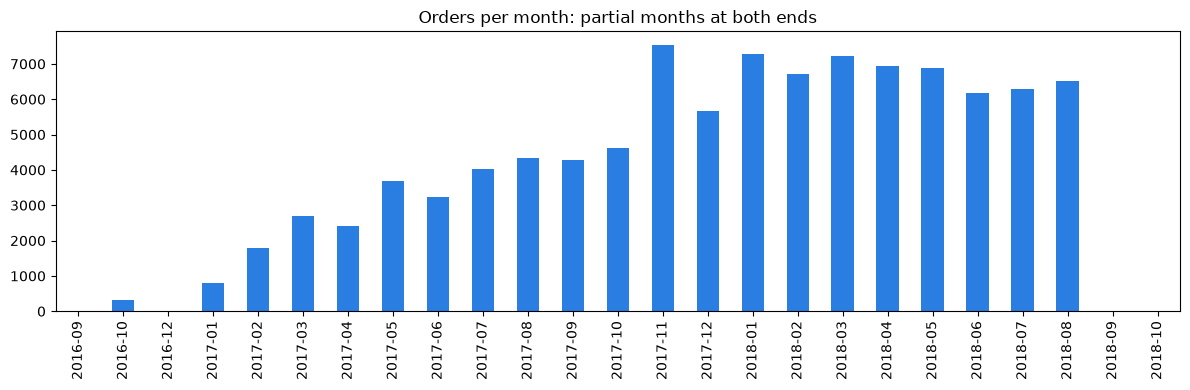

In [24]:
monthly = q("""
SELECT strftime(date_trunc('month', order_purchase_timestamp), '%Y-%m') AS month,
       count(*) AS orders
FROM raw.orders
GROUP BY month
ORDER BY month
""")
ax = monthly.plot.bar(x="month", y="orders", figsize=(12, 4), legend=False, color="#2a7de1")
ax.set_title("Orders per month: partial months at both ends")
ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Finding:** The data covers Sep 2016 to Oct 2018, but the first months (Sep–Dec 2016, with Nov 2016 missing completely) and the last two months (Sep–Oct 2018) contain only a handful of orders. They are partial months and should be excluded from month-over-month trends.

### 5.5 Product completeness check

#### Exercise 5

In [25]:
q("""
SELECT count(*)                                         AS products,
       count(*) FILTER (product_category_name IS NULL)  AS category_null,
       count(*) FILTER (product_weight_g IS NULL)       AS weight_null,
       count(*) FILTER (product_weight_g = 0)           AS weight_zero,
       count(DISTINCT product_category_name)            AS n_categories
FROM raw.products
""")

,products,category_null,weight_null,weight_zero,n_categories
0,32951,610,2,4,73


**Finding:** 610 products have no category (they would fall into an "unknown" member of a product dimension), 2 have no weight and 4 have a weight of 0 g, which is not a valid physical value. The catalogue uses 73 distinct categories.

## 6. Cardinality

For each relationship we count the child rows of **every** parent (a LEFT JOIN keeps parents with no children,
`count(child_column)` gives them 0). The minimum tells us whether the child side is optional (circle, min = 0)
or mandatory (bar, min = 1); the maximum tells us "one" (max = 1) or "many" (max > 1).

In [26]:
q("""
WITH children_per_parent AS (
    SELECT 'customers -> orders' AS relationship, count(o.order_id) AS n_children
      FROM raw.customers c LEFT JOIN raw.orders o USING (customer_id) GROUP BY c.customer_id
    UNION ALL SELECT 'orders -> order_items', count(i.order_id)
      FROM raw.orders o LEFT JOIN raw.order_items i USING (order_id) GROUP BY o.order_id
    UNION ALL SELECT 'products -> order_items', count(i.product_id)
      FROM raw.products p LEFT JOIN raw.order_items i USING (product_id) GROUP BY p.product_id
    UNION ALL SELECT 'sellers -> order_items', count(i.seller_id)
      FROM raw.sellers s LEFT JOIN raw.order_items i USING (seller_id) GROUP BY s.seller_id
)
SELECT relationship,
       min(n_children)                    AS min_children,
       max(n_children)                    AS max_children,
       count(*) FILTER (n_children = 0)   AS parents_without_children,
       round(avg(n_children), 2)          AS avg_children
FROM children_per_parent
GROUP BY relationship
ORDER BY relationship
""")

,relationship,min_children,max_children,parents_without_children,avg_children
0,customers -> orders,1,1,0,1.00
1,orders -> order_items,0,21,775,1.13
2,products -> order_items,1,527,0,3.42
3,sellers -> order_items,1,2033,0,36.40


The parent side is always **exactly one**: every FK is non-null and has no orphans (section 4).
On the child side:

| relationship | min | max | child side | crow's foot |
|---|---|---|---|---|
| customers → orders | 1 | 1 | exactly one (in this data) | `\|\|--\|{` drawn as one or many, see note |
| orders → order_items | 0 | 21 | zero or many | `\|\|--o{` |
| products → order_items | 1 | 527 | one or many | `\|\|--\|{` |
| sellers → order_items | 1 | 2033 | one or many | `\|\|--\|{` |

`customer_id` is generated per order, so the data shows exactly one order per `customer_id`. A real customer
(`customer_unique_id`) can place many orders, so the diagram uses "one or many": here the data is stricter than the diagram.
775 orders have no items, so the circle on orders → order_items is justified by the data.

### Hidden many-to-many relationships

`order_items` links orders to products and to sellers. The query below shows that both sides really are "many":

In [27]:
q("""
SELECT 'products per order' AS measure, max(n) AS max_n FROM (SELECT count(DISTINCT product_id) AS n FROM raw.order_items GROUP BY order_id)
UNION ALL SELECT 'orders per product', max(n) FROM (SELECT count(DISTINCT order_id)   AS n FROM raw.order_items GROUP BY product_id)
UNION ALL SELECT 'sellers per order',  max(n) FROM (SELECT count(DISTINCT seller_id)  AS n FROM raw.order_items GROUP BY order_id)
UNION ALL SELECT 'orders per seller',  max(n) FROM (SELECT count(DISTINCT order_id)   AS n FROM raw.order_items GROUP BY seller_id)
""")

,measure,max_n
0,products per order,8
1,orders per product,467
2,sellers per order,5
3,orders per seller,1854


### Customer identifiers

In [28]:
q("""
SELECT count(*)                           AS customer_rows,
       count(DISTINCT customer_id)        AS distinct_customer_id,
       count(DISTINCT customer_unique_id) AS distinct_customer_unique_id
FROM raw.customers
""")

,customer_rows,distinct_customer_id,distinct_customer_unique_id
0,99441,99441,96096


The ERD is in [`docs/erd.md`](../docs/erd.md) (image: `docs/erd.png`) and the short note in [`docs/assignment1_note.md`](../docs/assignment1_note.md).

In [29]:
con.close()